# Analiza podatkov Formule 1 (2018 – 2025)

### Seminarska naloga pri predmetu Uvod v programiranje

**Avtor:** Andrej Nedeljkovic\
**Vpisna številka:** 50180\
**Datum:** 27. 10. 2026

## 1. Uvod

V nalogi obdelam podatke dirk Formule 1 med sezonama 2018 in 2025. Podatke prenesem prek odprtega API-ja Jolpica (Ergast), surove odgovore shranim v lokalni predpomnilnik, jih pretvorim v tabele CSV in nato analiziram v tem zvezku.

Obdobje zajema nekaj večjih sprememb:

1. **2018–2020**: prevlada Mercedesa v hibridni dobi.
2. **2021**: izenačen dvoboj med Hamiltonom in Verstappnom.
3. **2022**: nova aerodinamična pravila (talni učinek) in začetek prevlade Red Bulla.
4. **2024–2025**: McLaren na vrhu konstruktorskega prvenstva.
5. **2021–2025**: sobotne sprint dirke.

Vprašanja, na katera skušam odgovoriti:

- kako se je menjala premoč med ekipami,
- kolikokrat je zmagal dirkač z najboljšega štartnega položaja in kako dobro štartno mesto napoveduje končno uvrstitev,
- kako dolgi so postanki v boksih in koliko postankov si ekipe privoščijo,
- kako se gibljejo hitrosti najhitrejših krogov na štirih dirkališčih,
- koliko točk prinašajo sprint dirke.

### Opombe o podatkih in uporabljenih orodjih

- Postanke v boksih prenašam le za pet vzorčnih dirk v vsaki sezoni (1., 5., 10., 15. in 20. krog koledarja). API namreč ponuja le postanke po posamezni dirki, branje vseh 24 dirk za osem sezon pa bi bilo prepočasno.
- Pri pisanju kode in besedila sem si pomagal z orodji umetne inteligence. Vse številke v besedilu sem prepisal iz izpisov, ki jih vrne ta zvezek.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.width", 140)

MAPA_PODATKOV = os.path.join("podatki", "obdelani")

In [2]:
TABELE = {
    "dirkaci": "lestvica_dirkaci.csv",
    "konstruktorji": "lestvica_konstruktorji.csv",
    "rezultati": "rezultati_dirk.csv",
    "kvalifikacije": "kvalifikacije.csv",
    "postanki": "postanki_v_boksih.csv",
    "sprinti": "sprint_dirke.csv",
}
tabele = {ime: pd.read_csv(os.path.join(MAPA_PODATKOV, datoteka)) for ime, datoteka in TABELE.items()}

for ime, tabela in tabele.items():
    print(f"{ime:<14} {tabela.shape[0]:>5} vrstic, {tabela.shape[1]:>2} stolpcev")

df_dirkaci = tabele["dirkaci"]
df_konstruktorji = tabele["konstruktorji"]
df_rezultati = tabele["rezultati"]
df_kvalifikacije = tabele["kvalifikacije"]
df_postanki = tabele["postanki"]
df_sprinti = tabele["sprinti"]

dirkaci          173 vrstic,  8 stolpcev
konstruktorji     80 vrstic,  7 stolpcev
rezultati       3458 vrstic, 20 stolpcev
kvalifikacije   3455 vrstic, 11 stolpcev
postanki        1442 vrstic,  7 stolpcev
sprinti          480 vrstic, 12 stolpcev


---
## 2. Dinamika prvenstev (2018–2025)

Najprej pogledam, kdo je bil svetovni prvak med dirkači in konstruktorji, nato pa še, kako so se gibale točke štirih ekip, ki so v tem obdobju posegle po naslovu: Mercedes, Red Bull, Ferrari in McLaren.

,sezona,ime_dirkaca,ekipa,tocke_dirkac,zmage,ime_konstruktorja,tocke_ekipa
0,2018,Lewis Hamilton,Mercedes,408.0,11,Mercedes,655.0
1,2019,Lewis Hamilton,Mercedes,413.0,11,Mercedes,739.0
2,2020,Lewis Hamilton,Mercedes,347.0,11,Mercedes,573.0
3,2021,Max Verstappen,Red Bull,395.5,10,Mercedes,613.5
4,2022,Max Verstappen,Red Bull,454.0,15,Red Bull,759.0
5,2023,Max Verstappen,Red Bull,575.0,19,Red Bull,860.0
6,2024,Max Verstappen,Red Bull,437.0,9,McLaren,666.0
7,2025,Lando Norris,McLaren,423.0,7,McLaren,833.0


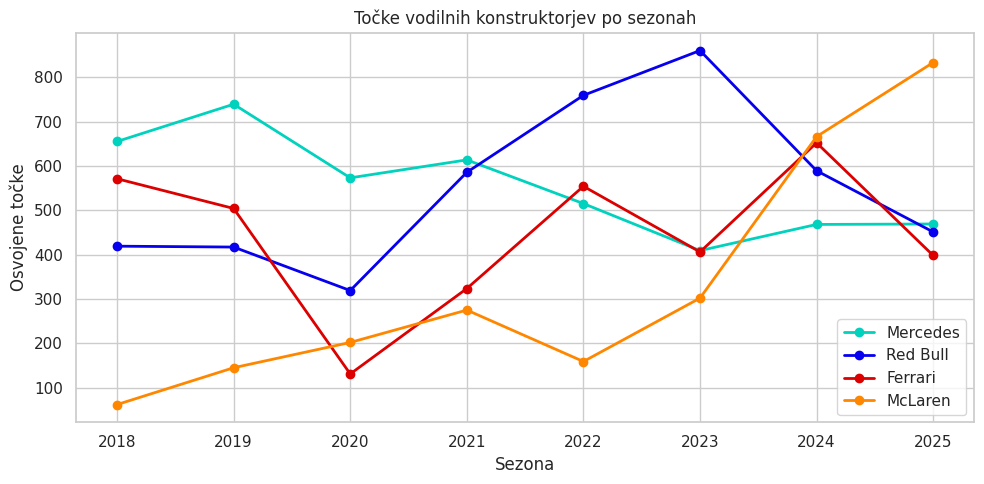

In [3]:
prvaki_dirkaci = df_dirkaci[df_dirkaci["uvrstitev"] == 1][
    ["sezona", "ime_dirkaca", "ekipa", "tocke", "zmage"]
].sort_values("sezona")
prvaki_ekipe = df_konstruktorji[df_konstruktorji["uvrstitev"] == 1][
    ["sezona", "ime_konstruktorja", "tocke"]
].sort_values("sezona")

prvaki = prvaki_dirkaci.merge(prvaki_ekipe, on="sezona", suffixes=("_dirkac", "_ekipa"))
display(prvaki)

barve = {"Mercedes": "#00D2BE", "Red Bull": "#0600EF", "Ferrari": "#DC0000", "McLaren": "#FF8700"}
plt.figure()
for ekipa in barve:
    podatki = df_konstruktorji[df_konstruktorji["ime_konstruktorja"] == ekipa].sort_values("sezona")
    plt.plot(podatki["sezona"], podatki["tocke"], marker="o", linewidth=2, color=barve[ekipa], label=ekipa)

plt.title("Točke vodilnih konstruktorjev po sezonah")
plt.xlabel("Sezona")
plt.ylabel("Osvojene točke")
plt.xticks(sorted(df_konstruktorji["sezona"].unique()))
plt.legend()
plt.tight_layout()
plt.show()

**Kaj pokaže graf:**

- Mercedes je dobil štiri zaporedne konstruktorske naslove (2018–2021); največ točk v tem nizu je zbral leta 2019 (739).
- Red Bull je po novih pravilih leta 2022 prevzel pobudo in leta 2023 zbral 860 točk.
- McLaren je slavil v letih 2024 (666 točk) in 2025 (833 točk). Ferrari je bil leta 2024 drugi (652 točk), leta 2025 pa šele četrti (398 točk), zato o izenačenem dvoboju McLarna in Ferrarija v celotnem obdobju ne morem govoriti.
- Pri dirkačih je med letoma 2021 in 2024 naslov osvojil Verstappen, leta 2025 pa Norris (423 točk), tik pred moštvenim kolegom Piastrijem (410).

---
## 3. Kvalifikacije in izkoristek najboljšega štartnega položaja

Zanima me, kako pogosto je dirko dobil dirkač, ki je bil najhitrejši v kvalifikacijah. Za "pole" vzamem prvo mesto v tabeli kvalifikacij (`kvalifikacije.csv`) in ne prvega štartnega mesta iz rezultatov, ker se ta dva podatka razlikujeta, kadar dirkač zaradi kazni štarta nižje.

,sezona,skupaj_dirk,zmag_iz_pola,delez_odstotki
0,2018,21,10,47.6
1,2019,21,8,38.1
2,2020,17,10,58.8
3,2021,22,12,54.5
4,2022,22,10,45.5
5,2023,22,15,68.2
6,2024,24,12,50.0
7,2025,24,16,66.7


Delež zmag z najboljšega štartnega mesta: 53.8% (93 od 173 dirk)


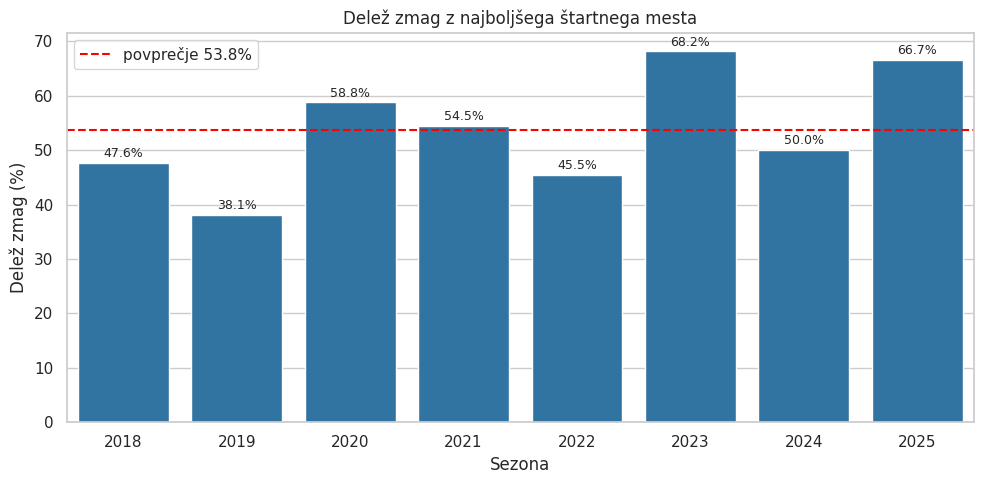

In [4]:
pole = df_kvalifikacije[df_kvalifikacije["uvrstitev_kvalifikacij"] == 1]
pole_rezultati = pole.merge(
    df_rezultati[["sezona", "stevilka_dirke", "id_dirkaca", "koncno_mesto"]],
    on=["sezona", "stevilka_dirke", "id_dirkaca"],
)
pole_rezultati["zmaga_iz_pola"] = (pole_rezultati["koncno_mesto"] == 1).astype(int)

statistika_pola = pole_rezultati.groupby("sezona").agg(
    skupaj_dirk=("zmaga_iz_pola", "size"),
    zmag_iz_pola=("zmaga_iz_pola", "sum"),
    delez=("zmaga_iz_pola", "mean"),
).reset_index()
statistika_pola["delez_odstotki"] = statistika_pola["delez"] * 100
display(statistika_pola.drop(columns="delez").round(1))

povprecje = pole_rezultati["zmaga_iz_pola"].mean() * 100
print(f"Delež zmag z najboljšega štartnega mesta: {povprecje:.1f}% "
      f"({pole_rezultati['zmaga_iz_pola'].sum()} od {len(pole_rezultati)} dirk)")

ax = sns.barplot(data=statistika_pola, x="sezona", y="delez_odstotki", color="#1f77b4")
ax.axhline(povprecje, color="red", linestyle="--", label=f"povprečje {povprecje:.1f}%")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2, fontsize=9)
ax.set(title="Delež zmag z najboljšega štartnega mesta", xlabel="Sezona", ylabel="Delež zmag (%)")
ax.legend()
plt.tight_layout()
plt.show()

Pearsonov koeficient med štartnim in končnim mestom: 0.620 (n = 3413)


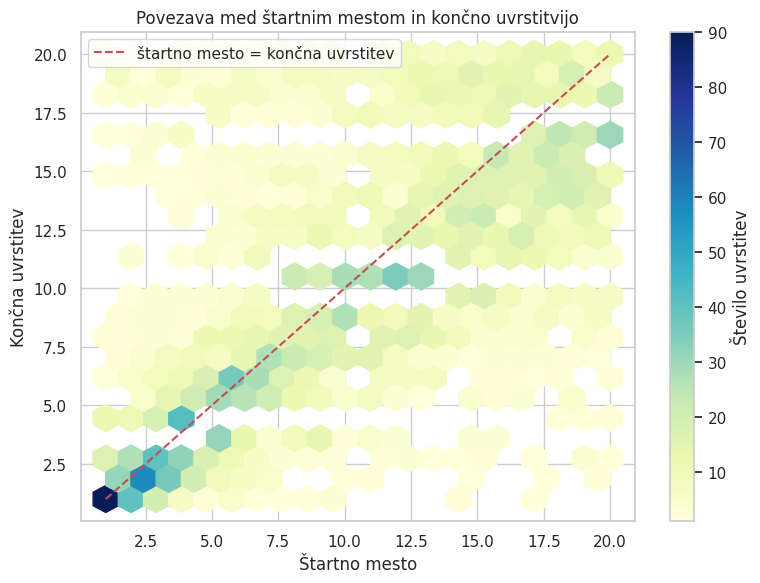

In [5]:
veljavne = df_rezultati[
    (df_rezultati["startno_mesto"] > 0)
    & df_rezultati["koncno_mesto"].notna()
    & (df_rezultati["koncno_mesto"] <= 20)
]
korelacija = veljavne["startno_mesto"].corr(veljavne["koncno_mesto"])
print(f"Pearsonov koeficient med štartnim in končnim mestom: {korelacija:.3f} (n = {len(veljavne)})")

plt.figure(figsize=(8, 6))
plt.hexbin(veljavne["startno_mesto"], veljavne["koncno_mesto"], gridsize=20, cmap="YlGnBu", mincnt=1)
plt.colorbar(label="Število uvrstitev")
plt.plot([1, 20], [1, 20], "r--", linewidth=1.5, label="štartno mesto = končna uvrstitev")
plt.title("Povezava med štartnim mestom in končno uvrstitvijo")
plt.xlabel("Štartno mesto")
plt.ylabel("Končna uvrstitev")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Kaj pokaže izračun:**

- Zmagovalec kvalifikacij je dirko dobil v **53,8 %** primerov (93 od 173 dirk). Če bi za pole vzeli prvo štartno mesto iz rezultatov, bi dobil 52,0 % – razlika so dirke, kjer je dirkač štartal nižje zaradi kazni.
- Najvišji delež je v letih 2023 (68,2 %) in 2025 (66,7 %), najnižjega pa v letih 2019 (38,1 %) in 2022 (45,5 %).
- Korelacija med štartnim in končnim mestom je **0,620**, kar je zmerna povezava: štart v ospredju pomaga, a dirke se pogosto končajo drugače (okvare, varnostni avtomobil, strategija).

---
## 4. Postanki v boksih

Postanek v boksih je eno redkih opravil, ki jih lahko neposredno izmerimo: gre za čas od vstopa v bokse do izstopa iz njih. V analizi obdržim postanke med 15 in 40 sekundami, s čimer izločim popravila dirkalnika in kazni.

Analiziranih postankov: 1311


count    1311.00
mean       24.53
std         4.28
min        15.00
25%        22.00
50%        23.90
75%        28.10
max        39.71
Name: trajanje_sekunde, dtype: float64

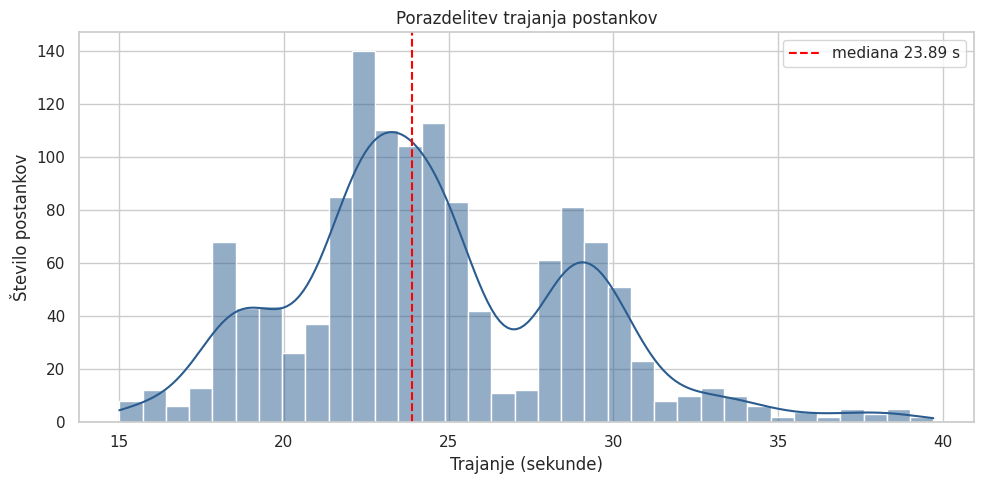

In [6]:
postanki = df_postanki[df_postanki["trajanje_sekunde"].between(15, 40)]
print(f"Analiziranih postankov: {len(postanki)}")
display(postanki["trajanje_sekunde"].describe().round(2))

mediana = postanki["trajanje_sekunde"].median()
ax = sns.histplot(postanki["trajanje_sekunde"], bins=35, kde=True, color="#2b5c8f")
ax.axvline(mediana, color="red", linestyle="--", label=f"mediana {mediana:.2f} s")
ax.set(title="Porazdelitev trajanja postankov", xlabel="Trajanje (sekunde)", ylabel="Število postankov")
ax.legend()
plt.tight_layout()
plt.show()

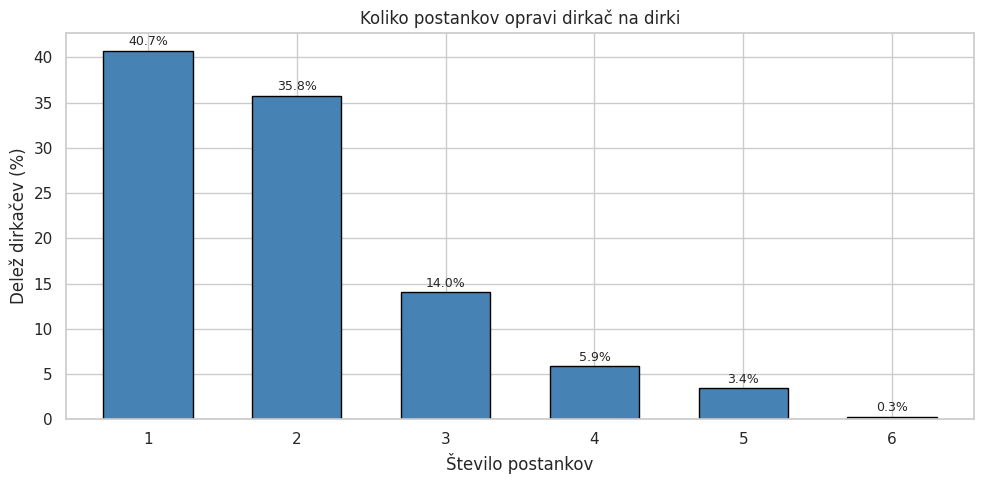

In [7]:
postanki_dirkaca = df_postanki.groupby(["sezona", "stevilka_dirke", "id_dirkaca"])["stevilka_postanka"].max()
delezi = postanki_dirkaca.value_counts(normalize=True).sort_index().mul(100)

ax = delezi.plot(kind="bar", color="#4682b4", edgecolor="black", width=0.6)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2, fontsize=9)
ax.set(title="Koliko postankov opravi dirkač na dirki", xlabel="Število postankov", ylabel="Delež dirkačev (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Kaj pokažeta grafa:**

- Mediana trajanja postanka je **23,9 s**, povprečje pa 24,5 s. Porazdelitev je rahlo razvlečena v desno, ker nekaj postankov traja tudi več kot 30 sekund.
- En postanek opravi **40,7 %** dirkačev, dva postanka **35,8 %**, tri 14,0 %, štiri ali več pa 9,6 %. Najpogostejša je torej ena menjava pnevmatik, a strategija z dvema postankoma ni redka.
- Upoštevati je treba, da štejem le dirkače, ki so vsaj enkrat postali, in da so med njimi tudi tisti, ki so pozneje odstopili. Podatki zajemajo samo pet vzorčnih dirk na sezono, zato gre za vzorec in ne za vse dirke.

---
## 5. Hitrosti najhitrejših krogov

Primerjam povprečno hitrost najhitrejšega kroga na štirih dirkališčih: Monza (hitra steza z majhnim aerodinamičnim uporom), Silverstone (hitri ovinki), Spa-Francorchamps (najdaljša steza) in Monako (ozka ulična steza).

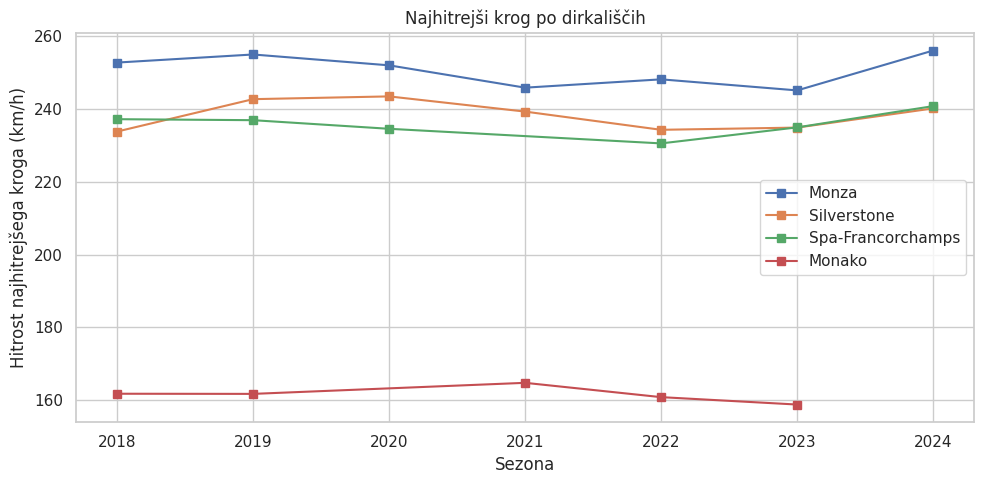

In [8]:
dirkalisca = {
    "monza": "Monza",
    "silverstone": "Silverstone",
    "spa": "Spa-Francorchamps",
    "monaco": "Monako",
}

hitrosti = df_rezultati[
    df_rezultati["id_dirkalisca"].isin(dirkalisca)
    & df_rezultati["hitrost_najhitrejsega_kroga_kmh"].notna()
]
hitrosti_max = hitrosti.groupby(["id_dirkalisca", "sezona"])["hitrost_najhitrejsega_kroga_kmh"].max().reset_index()

plt.figure()
for id_steze, oznaka in dirkalisca.items():
    podatki = hitrosti_max[hitrosti_max["id_dirkalisca"] == id_steze].sort_values("sezona")
    plt.plot(podatki["sezona"], podatki["hitrost_najhitrejsega_kroga_kmh"], marker="s", label=oznaka)

plt.title("Najhitrejši krog po dirkališčih")
plt.xlabel("Sezona")
plt.ylabel("Hitrost najhitrejšega kroga (km/h)")
plt.xticks(sorted(hitrosti_max["sezona"].unique()))
plt.legend()
plt.tight_layout()
plt.show()

**Kaj pokaže graf:**

- **Monza** je najhitrejše dirkališče v izboru, a 250 km/h ne preseže vsako leto: v letih 2018 (252,8), 2019 (255,0), 2020 (252,0) in 2024 (256,1) je bila hitrost višja, med letoma 2021 in 2023 pa je znašala med 245 in 248 km/h.
- Krivulje si ne sledijo enotno. V Monzi je hitrost leta 2022 narasla (s 245,9 na 248,2), leta 2023 padla (245,1) in leta 2024 spet narasla. V Silverstonu je po letu 2021 prav tako padla in se do leta 2024 vrnila na približno raven iz leta 2020. Iz grafa torej ne morem sklepati, da so pravila iz leta 2022 povzročila padec in nato dvig hitrosti – na hitrost najhitrejšega kroga vplivajo tudi vreme, izbira pnevmatik in potek dirke.
- **Monako** ostaja pri približno 160 km/h, kar je posledica ozke steze in odsotnosti dolgih ravnin.
- Podatki niso popolni: za leto 2025 v viru ni hitrosti najhitrejših krogov, zato se vse krivulje končajo leta 2024. Manjkajo tudi posamezne dirke (Monako 2020 je bil odpovedan, za Monako 2024 in Spa 2021 pa v viru ni podatka o najhitrejšem krogu), zato so črte med tema letoma narisane naravnost.

---
## 6. Sprint dirke (2021–2025)

Sprint je krajša dirka v soboto, ki prinaša dodatne točke. Leta 2021 so točke dobili le trije najboljši (3-2-1), od leta 2022 naprej pa prvih osem (8-7-…-1). Ker so v isti tabeli oba sistema, skupnih vsot ne gre brati kot popolnoma primerljive med leti.

,ime_dirkaca,stevilo_sprintov,tocke,zmage
0,Max Verstappen,24,143.0,13
1,Lando Norris,24,86.0,3
2,Charles Leclerc,24,84.0,0
3,George Russell,24,80.0,1
4,Carlos Sainz,24,79.0,0
5,Oscar Piastri,18,71.0,3
6,Lewis Hamilton,24,63.0,1
7,Sergio Pérez,18,53.0,1
8,Yuki Tsunoda,24,16.0,0
9,Andrea Kimi Antonelli,6,15.0,0


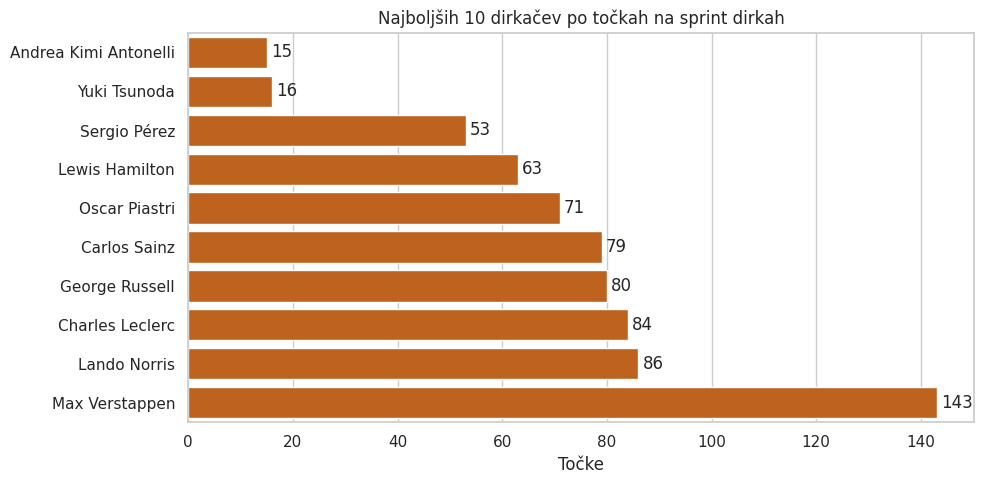

In [9]:
sprint_lestvica = (
    df_sprinti.groupby("ime_dirkaca")
    .agg(
        stevilo_sprintov=("stevilka_dirke", "count"),
        tocke=("tocke", "sum"),
        zmage=("koncno_mesto", lambda mesta: (mesta == 1).sum()),
    )
    .sort_values("tocke", ascending=False)
    .reset_index()
)

najboljsih = sprint_lestvica.head(10)
display(najboljsih)

ax = sns.barplot(data=najboljsih, y="ime_dirkaca", x="tocke", color="#d95f02")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
ax.invert_yaxis()
ax.set(title="Najboljših 10 dirkačev po točkah na sprint dirkah", xlabel="Točke", ylabel="")
plt.tight_layout()
plt.show()

**Kaj pokaže tabela:**

- **Max Verstappen** je zbral največ sprint točk: 143 točk na 24 sprintih (toliko sprintov je odvozil v celotnem obdobju).
- Sledijo Norris (86), Leclerc (84), Russell (80) in Sainz (79). Piastri in Pérez sta odvozila po 18 sprintov, ker nista bila v prvenstvu vseh pet sezon (Piastri je začel leta 2023, Pérez pa je po letu 2024 odšel).
- V enem sprintu je na voljo 36 točk (8+7+…+1), v sezoni s šestimi sprinti torej do 216 skupnih točk. Največ točk v eni sezoni je zbral Verstappen leta 2023 (45).

---
## 7. Omejitve analize

- Postanki so zajeti le za pet vzorčnih dirk na sezono (glej poglavje 1).
- Hitrosti najhitrejših krogov za leto 2025 v viru ni, zato se ta del analize konča leta 2024.
- Sprint točke mešajo dva različna točkovna sistema (2021 in 2022–2025).
- Pri številu postankov štejem le dirkače, ki so vsaj enkrat postali; med njimi so tudi odstopi.
- "Pole" pomeni prvo mesto v kvalifikacijah in ne prvega štartnega mesta, ki se lahko zaradi kazni razlikuje.

---
## 8. Sklep

1. **Menjava obdobij prevlade**: Mercedes je bil najmočnejši do leta 2021, Red Bull je prevzel pobudo po letu 2022 (leta 2023 že 860 točk), v letih 2024 in 2025 pa je bil najboljši McLaren (666 in 833 točk). Ferrari je leta 2024 končal drugi, leta 2025 pa četrti.
2. **Kvalifikacije**: zmagovalec kvalifikacij je dobil 53,8 % dirk (93 od 173), največ v letih 2023 (68,2 %) in 2025 (66,7 %). Korelacija med štartnim in končnim mestom je 0,620.
3. **Postanki**: mediana postanka je 23,9 s, najpogostejša strategija pa je en postanek (40,7 %), tesno ji sledita dva postanka (35,8 %).
4. **Hitrosti**: Monza je najhitrejše dirkališče, a 250 km/h ne preseže vsako leto; krivulje se med dirkališči in leti ne gibljejo enotno, zato iz njih ne morem potegniti zaključka o neposrednem vplivu pravil leta 2022.
5. **Sprinti**: sprint dirke prinašajo do 36 točk na dirko; največ jih je zbral Verstappen (143 v petih sezonah).